# Assignment Beta - Question 2
### Parameter-efficient fine-tuning for tool calling: LoRA vs QLoRA vs DoRA vs AdaLoRA
Ibrahim Johar Farooqi - 23K-0074 - BAI-7A

Base model: **Qwen2.5-1.5B-Instruct**. Data: 2,000 examples from **glaive-function-calling-v2** (1,800 train / 200 held-out test).
Everything is identical across runs (data, seed, epochs, LR schedule, target modules, batch size). Only the adaptation method changes.

Runs on a free **Colab T4** (Runtime > Change runtime type > T4 GPU). T4 has no bf16, so "bf16/fp16" runs use fp16 here.
Results are saved to Google Drive after every run, so if Colab disconnects just re-run all cells and finished runs are skipped.

In [1]:
!pip install -q -U transformers peft bitsandbytes datasets accelerate
!pip uninstall -y -q torchao

In [2]:
import os, re, json, time, math, random, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig, get_cosine_schedule_with_warmup
from peft import LoraConfig, AdaLoraConfig, get_peft_model, prepare_model_for_kbit_training, PeftModel
import transformers, peft
print("torch", torch.__version__, "| transformers", transformers.__version__, "| peft", peft.__version__)

torch 2.14.1+cu130 | transformers 5.23.0 | peft 0.21.3


In [3]:
MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"
DATASET_ID = "glaiveai/glaive-function-calling-v2"

SEED = 42
N_TOTAL, N_TEST = 2000, 200
MAX_LEN = 768          # examples longer than this are dropped before sampling, so nothing gets truncated
EPOCHS = 2
BATCH, GRAD_ACC = 4, 4 # effective batch 16
LR = 2e-4
WARMUP_RATIO = 0.05
LORA_DROPOUT = 0.05
TARGET_MODULES = ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]
MAX_NEW_TOKENS = 200
EVAL_BATCH = 16

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
# T4 is compute capability 7.5 -> no native bf16, use fp16
DTYPE = torch.bfloat16 if DEVICE == "cuda" and torch.cuda.get_device_capability()[0] >= 8 else torch.float16
if DEVICE == "cpu":
    DTYPE = torch.float32
print(DEVICE, DTYPE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

try:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT = "/content/drive/MyDrive/AssignmentBeta_Q2"
except Exception:
    OUT = "results"
os.makedirs(f"{OUT}/adapters", exist_ok=True)
print("saving to", OUT)

def seed_everything(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if DEVICE == "cuda":
        torch.cuda.manual_seed_all(s)
seed_everything()

cuda torch.float16 Tesla T4
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
saving to /content/drive/MyDrive/AssignmentBeta_Q2


## Section 1 (theory)

Answers to (a)-(d) are written out in the report. Quick check of the arithmetic for (a) and (b):

In [4]:
d, k, r = 4096, 4096, 16
lora_params = r * k + d * r          # A is r x k, B is d x r
print("A:", r * k, " B:", d * r, " total:", lora_params)
print("original:", d * k, " percentage:", round(100 * lora_params / (d * k), 4), "%")

A: 65536  B: 65536  total: 131072
original: 16777216  percentage: 0.7812 %


## Data

Each glaive sample has a `system` field (the available functions as JSON) and a `chat` field (`USER: ... ASSISTANT: <functioncall> {...}`).
I keep samples where the **first** assistant turn is a function call, and turn that call into strict JSON:
`{"name": ..., "arguments": {...}}` (glaive stores `arguments` as a single-quoted string, which isn't valid JSON).

In [5]:
raw = load_dataset(DATASET_ID, split="train")
print(raw)
print(raw[0]["system"][:400])
print(raw[0]["chat"][:400])

Dataset({
    features: ['system', 'chat'],
    num_rows: 112960
})
SYSTEM: You are a helpful assistant with access to the following functions. Use them if required -
{
    "name": "get_exchange_rate",
    "description": "Get the exchange rate between two currencies",
    "parameters": {
        "type": "object",
        "properties": {
            "base_currency": {
                "type": "string",
                "description": "The currency to convert from"
  
USER: Can you book a flight for me from New York to London?


ASSISTANT: I'm sorry, but I don't have the capability to book flights. My current function allows me to get the exchange rate between two currencies. If you need help with that, feel free to ask! <|endoftext|>





In [6]:
decoder = json.JSONDecoder()

def parse_functions(system):
    if "-" not in system:
        return []
    text = system.split("-", 1)[1]
    funcs, i = [], 0
    while True:
        j = text.find("{", i)
        if j == -1:
            break
        try:
            obj, end = decoder.raw_decode(text, j)
        except json.JSONDecodeError:
            break
        if isinstance(obj, dict) and "name" in obj:
            funcs.append(obj)
        i = end
    return funcs

def parse_first_turn(chat):
    m = re.search(r"USER:\s*(.*?)\s*ASSISTANT:\s*(.*?)(?:<\|endoftext\|>|\n\n\nFUNCTION RESPONSE|\n\n\nUSER:|$)", chat, re.S)
    if not m:
        return None
    user, reply = m.group(1).strip(), m.group(2).strip()
    if not reply.startswith("<functioncall>"):
        return None
    body = reply[len("<functioncall>"):].strip()
    m2 = re.match(r'\{\s*"name"\s*:\s*"([^"]+)"\s*,\s*"arguments"\s*:\s*\'(.*)\'\s*\}$', body, re.S)
    try:
        if m2:
            name, args = m2.group(1), json.loads(m2.group(2))
        else:
            obj = json.loads(body)
            name, args = obj["name"], obj["arguments"]
            if isinstance(args, str):
                args = json.loads(args)
    except Exception:
        return None
    if not isinstance(args, dict):
        return None
    return user, {"name": name, "arguments": args}

examples = []
for row in raw:
    funcs = parse_functions(row["system"])
    if not funcs:
        continue
    parsed = parse_first_turn(row["chat"])
    if parsed is None:
        continue
    user, call = parsed
    if call["name"] not in {f["name"] for f in funcs}:
        continue
    examples.append({"functions": funcs, "user": user, "call": call})

print("usable examples:", len(examples))
examples[0]

usable examples: 37755


{'functions': [{'name': 'get_news_headlines',
   'description': 'Get the latest news headlines',
   'parameters': {'type': 'object',
    'properties': {'country': {'type': 'string',
      'description': 'The country for which to fetch news'}},
    'required': ['country']}}],
 'user': 'Can you tell me the latest news headlines for the United States?',
 'call': {'name': 'get_news_headlines',
  'arguments': {'country': 'United States'}}}

In [7]:
tok = AutoTokenizer.from_pretrained(MODEL_ID)
if tok.pad_token is None:
    tok.pad_token = tok.eos_token
END_ID = tok.convert_tokens_to_ids("<|im_end|>")

INSTRUCTION = (
    "You are a customer-support assistant that can call backend functions.\n"
    "Available functions:\n{functions}\n\n"
    "If a function is needed, reply with ONLY a JSON object of the form "
    '{{"name": "<function name>", "arguments": {{"<argument>": <value>}}}}. '
    "Use only the functions listed above and do not add any text before or after the JSON."
)

def build_prompt(functions, user):
    msgs = [{"role": "system", "content": INSTRUCTION.format(functions=json.dumps(functions))},
            {"role": "user", "content": user}]
    return tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)

def encode(ex):
    prompt = build_prompt(ex["functions"], ex["user"])
    target = json.dumps(ex["call"]) + "<|im_end|>"
    p_ids = tok(prompt, add_special_tokens=False)["input_ids"]
    t_ids = tok(target, add_special_tokens=False)["input_ids"]
    return {"input_ids": p_ids + t_ids, "labels": [-100] * len(p_ids) + t_ids, "prompt": prompt}

for ex in examples:
    ex.update(encode(ex))
fits = [ex for ex in examples if len(ex["input_ids"]) <= MAX_LEN]
print(f"{len(fits)} of {len(examples)} fit in {MAX_LEN} tokens")

rng = random.Random(SEED)
rng.shuffle(fits)
subset = fits[:N_TOTAL]
test_set, train_set = subset[:N_TEST], subset[N_TEST:]
print("train:", len(train_set), " test:", len(test_set))
print("train token lengths: mean", int(np.mean([len(e["input_ids"]) for e in train_set])), " max", max(len(e["input_ids"]) for e in train_set))

json.dump([{"user": e["user"], "functions": e["functions"], "call": e["call"]} for e in test_set],
          open(f"{OUT}/test_set.json", "w"), indent=1)

37755 of 37755 fit in 768 tokens
train: 1800  test: 200
train token lengths: mean 243  max 530


In [8]:
print(train_set[0]["prompt"])
print(json.dumps(train_set[0]["call"]))

<|im_start|>system
You are a customer-support assistant that can call backend functions.
Available functions:
[{"name": "get_movie_details", "description": "Get details of a movie", "parameters": {"type": "object", "properties": {"title": {"type": "string", "description": "The title of the movie"}, "year": {"type": "integer", "description": "The year the movie was released"}}, "required": ["title", "year"]}}]

If a function is needed, reply with ONLY a JSON object of the form {"name": "<function name>", "arguments": {"<argument>": <value>}}. Use only the functions listed above and do not add any text before or after the JSON.<|im_end|>
<|im_start|>user
Can you tell me about the movie "Inception" released in 2010?<|im_end|>
<|im_start|>assistant

{"name": "get_movie_details", "arguments": {"title": "Inception", "year": 2010}}


### Customer-support probe

glaive doesn't have the startup's four functions, so on top of the 200 test examples I also check every model on 16 hand-written
support messages using `check_order_status`, `initiate_refund`, `track_shipment` and `escalate_to_human`.
These include the case from the brief (asking about delivery date should **not** trigger a refund).
This is a small extra check, not part of the 200-example metrics.

In [9]:
SUPPORT_FUNCS = [
    {"name": "check_order_status", "description": "Get the current status and expected delivery date of an order",
     "parameters": {"type": "object", "properties": {"order_id": {"type": "string"}}, "required": ["order_id"]}},
    {"name": "initiate_refund", "description": "Start a refund for an order. Only use when the customer explicitly asks for their money back",
     "parameters": {"type": "object", "properties": {"order_id": {"type": "string"}, "reason": {"type": "string"}}, "required": ["order_id", "reason"]}},
    {"name": "track_shipment", "description": "Get the live courier tracking location for a shipment",
     "parameters": {"type": "object", "properties": {"tracking_number": {"type": "string"}}, "required": ["tracking_number"]}},
    {"name": "escalate_to_human", "description": "Hand the conversation to a human agent",
     "parameters": {"type": "object", "properties": {"summary": {"type": "string"}}, "required": ["summary"]}},
]
PROBES = [
    ("Where is my order 58213? I placed it last Tuesday.", "check_order_status"),
    ("When will order 77120 be delivered?", "check_order_status"),
    ("Has my order A-4410 shipped yet?", "check_order_status"),
    ("Can you tell me the expected delivery date for order 99031? I need it before Friday.", "check_order_status"),
    ("I want my money back for order 33102, the shoes were the wrong size.", "initiate_refund"),
    ("Please refund order 55017, the blender arrived broken.", "initiate_refund"),
    ("Order 12009 never arrived and I'd like a refund.", "initiate_refund"),
    ("Cancel and refund order 64400, I was charged twice.", "initiate_refund"),
    ("Track parcel TRK-883920 for me.", "track_shipment"),
    ("Where exactly is the courier with tracking number LP00912PK right now?", "track_shipment"),
    ("My tracking number is 7781-2290, what city is the package in?", "track_shipment"),
    ("Can you check tracking ZX55102 please?", "track_shipment"),
    ("This is the third time I'm writing, I want to speak to a real person.", "escalate_to_human"),
    ("Your bot is useless, connect me to a manager.", "escalate_to_human"),
    ("I need to talk to someone about a legal complaint regarding my account.", "escalate_to_human"),
    ("None of these options help, please get me an agent.", "escalate_to_human"),
]
probe_prompts = [build_prompt(SUPPORT_FUNCS, q) for q, _ in PROBES]

## Evaluation helpers

- **JSON valid**: the whole output parses with `json.loads()` (strict, as the brief asks)
- **Tool accuracy**: the function name is correct. I read the name from the first `{...}` block even if there's extra text around it, so this measures *choosing* the tool separately from formatting.
- **Full match**: output is valid JSON **and** the name **and** every argument (keys and values) match exactly. This is the strict "the backend can execute it" number.
- Also tracked: made-up function names (not in the available list), extra text around the JSON, and outputs with no JSON at all.

In [10]:
def extract_json(text):
    i = text.find("{")
    while i != -1:
        try:
            obj, _ = decoder.raw_decode(text, i)
            if isinstance(obj, dict):
                return obj
        except json.JSONDecodeError:
            pass
        i = text.find("{", i + 1)
    return None

def norm_args(a):
    if isinstance(a, str):
        try:
            a = json.loads(a)
        except Exception:
            return a
    return a

def score_one(pred, gold, allowed):
    out = pred.strip()
    try:
        strict = json.loads(out)
        valid = isinstance(strict, dict)
    except Exception:
        strict, valid = None, False
    loose = strict if valid else extract_json(out)
    name = loose.get("name") if isinstance(loose, dict) else None
    args = norm_args(loose.get("arguments")) if isinstance(loose, dict) else None
    tool_ok = name == gold["name"]
    full = valid and tool_ok and args == gold["arguments"]
    return {"json_valid": valid, "tool_correct": tool_ok, "full_match": full,
            "made_up_name": name is not None and name not in allowed,
            "extra_text": (not valid) and loose is not None,
            "no_json": loose is None, "has_brace": "{" in out, "pred_name": name, "pred_args": args}

def error_type(rec, gold):
    if rec["no_json"]:
        return "broken JSON" if rec["has_brace"] else "refused / answered in text"
    if not rec["json_valid"] and not rec["tool_correct"]:
        return "broken JSON"
    if rec["made_up_name"]:
        return "made-up function"
    if not rec["tool_correct"]:
        return "wrong tool"
    args = rec["pred_args"] if isinstance(rec["pred_args"], dict) else {}
    extra = set(args) - set(gold["arguments"])
    missing = set(gold["arguments"]) - set(args)
    if not rec["json_valid"]:
        return "extra text around JSON"
    if extra:
        return "made-up argument"
    if missing:
        return "missing argument"
    return "wrong argument value"

In [11]:
@torch.no_grad()
def generate(model, prompts, bs=EVAL_BATCH):
    tok.padding_side = "left"
    model.eval()
    try:
        model.gradient_checkpointing_disable()
    except Exception:
        pass
    model.config.use_cache = True
    outs, n_new = [], 0
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    for i in range(0, len(prompts), bs):
        enc = tok(prompts[i:i + bs], return_tensors="pt", padding=True, add_special_tokens=False).to(DEVICE)
        with torch.autocast(DEVICE, dtype=DTYPE, enabled=DEVICE == "cuda"):
            gen = model.generate(**enc, max_new_tokens=MAX_NEW_TOKENS, do_sample=False, temperature=None, top_p=None, top_k=None,
                                 pad_token_id=tok.pad_token_id, eos_token_id=[END_ID, tok.eos_token_id])
        new = gen[:, enc["input_ids"].shape[1]:]
        for row in new:
            keep = row[(row != tok.pad_token_id) & (row != END_ID)]
            n_new += len(keep)
            outs.append(tok.decode(keep, skip_special_tokens=True))
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    secs = time.perf_counter() - t0
    return outs, secs, n_new

def evaluate(model, name):
    preds, secs, n_new = generate(model, [e["prompt"] for e in test_set])
    recs = []
    for e, p in zip(test_set, preds):
        r = score_one(p, e["call"], {f["name"] for f in e["functions"]})
        r.update({"user": e["user"], "gold": e["call"], "pred": p})
        if not r["full_match"]:
            r["error_type"] = error_type(r, e["call"])
        recs.append(r)
    with open(f"{OUT}/{name}_preds.jsonl", "w") as f:
        for r in recs:
            f.write(json.dumps(r) + "\n")

    probe_out, _, _ = generate(model, probe_prompts)
    probe_recs = [score_one(p, {"name": g, "arguments": {}}, {f["name"] for f in SUPPORT_FUNCS}) | {"query": q, "gold": g, "pred": p}
                  for (q, g), p in zip(PROBES, probe_out)]
    json.dump(probe_recs, open(f"{OUT}/{name}_probe.json", "w"), indent=1)

    n = len(recs)
    m = {"json_valid": sum(r["json_valid"] for r in recs), "tool_correct": sum(r["tool_correct"] for r in recs),
         "full_match": sum(r["full_match"] for r in recs), "made_up_name": sum(r["made_up_name"] for r in recs),
         "extra_text": sum(r["extra_text"] for r in recs), "no_json": sum(r["no_json"] for r in recs),
         "gen_tokens_per_s": n_new / secs, "eval_seconds": secs,
         "probe_tool_acc": sum(r["tool_correct"] for r in probe_recs) / len(probe_recs),
         "probe_wrong_refunds": sum(r["pred_name"] == "initiate_refund" and r["gold"] != "initiate_refund" for r in probe_recs)}
    for k in ["json_valid", "tool_correct", "full_match"]:
        m[k + "_pct"] = 100 * m[k] / n
    return m

## Training

Plain PyTorch loop so every run goes through exactly the same code. Loss is only on the JSON answer tokens (prompt tokens are masked with -100).
AdamW, cosine schedule with 5% warmup, gradient clipping at 1.0, gradient checkpointing on for all runs.
QLoRA uses bitsandbytes' paged AdamW, which is the same AdamW update but can page optimizer state to CPU RAM on memory spikes.

AdaLoRA needs `update_and_allocate()` after every optimizer step (before the gradients are cleared) so it can score
each singular value's importance and prune the rank budget from 12 down to 8.

In [12]:
def load_base(quant):
    if quant:
        bnb_cfg = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                     bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=DTYPE)
        model = AutoModelForCausalLM.from_pretrained(MODEL_ID, quantization_config=bnb_cfg, device_map={"": 0}, dtype=DTYPE)
        model = prepare_model_for_kbit_training(model, use_gradient_checkpointing=True,
                                                gradient_checkpointing_kwargs={"use_reentrant": False})
    else:
        model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=DTYPE).to(DEVICE)
        model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
        model.enable_input_require_grads()
    model.config.use_cache = False
    return model

def make_config(method, r, total_steps):
    common = dict(lora_alpha=2 * r, lora_dropout=LORA_DROPOUT, target_modules=TARGET_MODULES, bias="none", task_type="CAUSAL_LM")
    if method == "adalora":
        return AdaLoraConfig(init_r=int(1.5 * r), target_r=r, tinit=int(0.1 * total_steps), tfinal=int(0.2 * total_steps),
                             deltaT=5, beta1=0.85, beta2=0.85, orth_reg_weight=0.5, total_step=total_steps, **common)
    return LoraConfig(r=r, use_dora=(method == "dora"), **common)

def batches(data, order):
    for i in range(0, len(order), BATCH):
        items = [data[j] for j in order[i:i + BATCH]]
        L = max(len(x["input_ids"]) for x in items)
        ids = torch.full((len(items), L), tok.pad_token_id)
        lab = torch.full((len(items), L), -100)
        att = torch.zeros((len(items), L), dtype=torch.long)
        for b, x in enumerate(items):
            n = len(x["input_ids"])
            ids[b, :n] = torch.tensor(x["input_ids"]); lab[b, :n] = torch.tensor(x["labels"]); att[b, :n] = 1
        yield {"input_ids": ids.to(DEVICE), "labels": lab.to(DEVICE), "attention_mask": att.to(DEVICE)}

def count_params(model):
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return trainable

In [13]:
def train_run(name, method, r):
    if os.path.exists(f"{OUT}/{name}.json"):
        print("already done:", name)
        return json.load(open(f"{OUT}/{name}.json"))
    seed_everything()
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()

    quant = method == "qlora"
    total_steps = (math.ceil(len(train_set) / BATCH) * EPOCHS) // GRAD_ACC
    model = load_base(quant)
    model = get_peft_model(model, make_config(method, r, total_steps))
    trainable = count_params(model)
    print(f"{name}: trainable {trainable:,} = {100 * trainable / BASE_PARAMS:.4f}% of base")

    params = [p for p in model.parameters() if p.requires_grad]
    if quant:
        import bitsandbytes as bnb
        opt = bnb.optim.PagedAdamW32bit(params, lr=LR, weight_decay=0.0)
    else:
        opt = torch.optim.AdamW(params, lr=LR, weight_decay=0.0)
    sched = get_cosine_schedule_with_warmup(opt, int(WARMUP_RATIO * total_steps), total_steps)
    scaler = torch.amp.GradScaler(DEVICE, init_scale=2 ** 10, enabled=(DTYPE == torch.float16))

    model.train()
    g = torch.Generator().manual_seed(SEED)
    step, micro, losses = 0, 0, []
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    for epoch in range(EPOCHS):
        order = torch.randperm(len(train_set), generator=g).tolist()
        for batch in batches(train_set, order):
            with torch.autocast(DEVICE, dtype=DTYPE, enabled=DEVICE == "cuda"):
                loss = model(**batch).loss / GRAD_ACC
            scaler.scale(loss).backward()
            losses.append(loss.item() * GRAD_ACC)
            micro += 1
            if micro % GRAD_ACC == 0:
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(params, 1.0)
                scaler.step(opt)
                scaler.update()
                if method == "adalora" and all(torch.isfinite(p.grad).all() for p in params if p.grad is not None):
                    model.base_model.update_and_allocate(step)
                opt.zero_grad(set_to_none=True)
                sched.step()
                step += 1
                if step % 20 == 0 or step == 1:
                    print(f"  step {step}/{total_steps}  loss {np.mean(losses[-GRAD_ACC * 10:]):.4f}")
                if step >= total_steps:
                    break
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    train_min = (time.perf_counter() - t0) / 60
    peak_gb = torch.cuda.max_memory_allocated() / 1024 ** 3 if DEVICE == "cuda" else float("nan")

    model.save_pretrained(f"{OUT}/adapters/{name}")
    if method == "adalora":
        pattern = model.peft_config["default"].rank_pattern or {}
        ranks = {k: int(sum(v)) for k, v in pattern.items()}
    else:
        ranks = {}

    res = {"run": name, "method": method, "r": r, "trainable_params": trainable,
           "trainable_pct": 100 * trainable / BASE_PARAMS, "peak_train_mem_gb": peak_gb,
           "train_minutes": train_min, "final_loss": float(np.mean(losses[-GRAD_ACC * 10:])), "steps": step,
           "base_precision": "4-bit NF4" if quant else str(DTYPE).replace("torch.", "")}
    if ranks:
        res["adalora_mean_final_rank"] = float(np.mean(list(ranks.values())))
        res["adalora_rank_min_max"] = [min(ranks.values()), max(ranks.values())]
    res.update(evaluate(model, name))
    json.dump(res, open(f"{OUT}/{name}.json", "w"), indent=1)
    json.dump(losses, open(f"{OUT}/{name}_losses.json", "w"))
    print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in res.items()})
    del model, opt
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    return res

## Run 0: base model, no fine-tuning (the "before" picture)

In [14]:
if os.path.exists(f"{OUT}/base.json"):
    base_res = json.load(open(f"{OUT}/base.json"))
    BASE_PARAMS = base_res["total_params"]
else:
    base = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=DTYPE).to(DEVICE)
    BASE_PARAMS = sum(p.numel() for p in base.parameters())
    base_res = {"run": "base", "method": "none", "r": 0, "trainable_params": 0, "trainable_pct": 0.0,
                "peak_train_mem_gb": float("nan"), "train_minutes": 0.0, "total_params": BASE_PARAMS,
                "base_precision": str(DTYPE).replace("torch.", "")}
    base_res.update(evaluate(base, "base"))
    json.dump(base_res, open(f"{OUT}/base.json", "w"), indent=1)
    del base; gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
print(f"base model parameters: {BASE_PARAMS:,}")
base_res

base model parameters: 1,543,714,304


{'run': 'base',
 'method': 'none',
 'r': 0,
 'trainable_params': 0,
 'trainable_pct': 0.0,
 'peak_train_mem_gb': nan,
 'train_minutes': 0.0,
 'total_params': 1543714304,
 'base_precision': 'float16',
 'json_valid': 200,
 'tool_correct': 200,
 'full_match': 182,
 'made_up_name': 0,
 'extra_text': 0,
 'no_json': 0,
 'gen_tokens_per_s': 155.92540920347142,
 'eval_seconds': 34.503677287000016,
 'probe_tool_acc': 0.875,
 'probe_wrong_refunds': 0,
 'json_valid_pct': 100.0,
 'tool_correct_pct': 100.0,
 'full_match_pct': 91.0}

## Section 2: four methods, rank 8

In [15]:
RUNS = [("lora_r8", "lora", 8), ("qlora_r8", "qlora", 8), ("dora_r8", "dora", 8), ("adalora_r8", "adalora", 8)]
results = {"base": base_res}
for name, method, r in RUNS:
    results[name] = train_run(name, method, r)

already done: lora_r8
already done: qlora_r8
already done: dora_r8
already done: adalora_r8


In [16]:
cols = ["run", "base_precision", "r", "trainable_params", "trainable_pct", "peak_train_mem_gb", "train_minutes",
        "json_valid", "tool_correct", "full_match", "made_up_name", "extra_text", "no_json", "gen_tokens_per_s",
        "probe_tool_acc", "probe_wrong_refunds"]
sec2 = pd.DataFrame([results[k] for k in ["base"] + [n for n, _, _ in RUNS]])[cols]
sec2.to_csv(f"{OUT}/results_section2.csv", index=False)
sec2.round(3)

,run,base_precision,r,trainable_params,trainable_pct,peak_train_mem_gb,train_minutes,json_valid,tool_correct,full_match,made_up_name,extra_text,no_json,gen_tokens_per_s,probe_tool_acc,probe_wrong_refunds
0,base,float16,0,0,0.000,NaN,0.000,200,200,182,0,0,0,155.925,0.875,0
1,lora_r8,float16,8,9232384,0.598,6.813,14.906,200,200,193,0,0,0,84.939,0.875,0
2,qlora_r8,4-bit NF4,8,9232384,0.598,6.052,19.271,200,200,192,0,0,0,60.831,0.812,0
3,dora_r8,float16,8,9877504,0.640,6.823,41.524,200,200,193,0,0,0,19.650,0.875,0
4,adalora_r8,float16,8,13851124,0.897,7.038,22.606,200,200,186,0,0,0,67.806,0.875,0


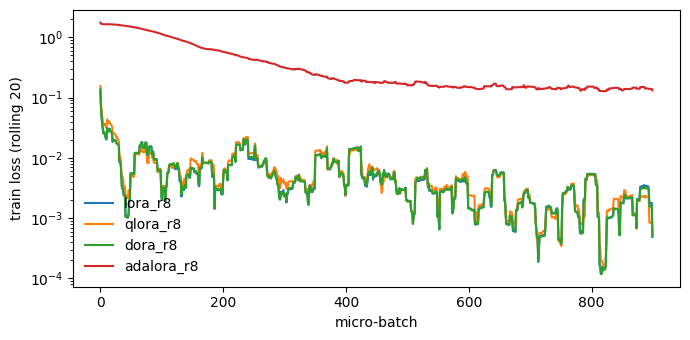

In [17]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for name, _, _ in RUNS:
    l = json.load(open(f"{OUT}/{name}_losses.json"))
    ax.plot(pd.Series(l).rolling(20, min_periods=1).mean(), label=name)
ax.set_xlabel("micro-batch"); ax.set_ylabel("train loss (rolling 20)")
ax.set_yscale("log"); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(f"{OUT}/loss_curves.png", dpi=200); plt.show()

### Merging check (for Section 4, question 5)

QLoRA's adapter was trained against the **4-bit** weights. To ship without bitsandbytes you'd merge it into the **fp16** base,
which is not the matrix it was trained on. DoRA's magnitude and direction fold into a single matrix on merge, so it should be lossless.
Here I merge the LoRA, QLoRA and DoRA adapters into the fp16 base, re-run the test set, and compare accuracy and generation speed against the unmerged versions.

In [18]:
def eval_merged(name):
    out_name = f"{name}_merged_fp16"
    if os.path.exists(f"{OUT}/{out_name}.json"):
        return json.load(open(f"{OUT}/{out_name}.json"))
    base = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=DTYPE).to(DEVICE)
    merged = PeftModel.from_pretrained(base, f"{OUT}/adapters/{name}").merge_and_unload()
    res = {"run": out_name}
    res.update(evaluate(merged, out_name))
    json.dump(res, open(f"{OUT}/{out_name}.json", "w"), indent=1)
    del base, merged; gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    return res

merge_rows = []
for name in ["lora_r8", "qlora_r8", "dora_r8"]:
    m = eval_merged(name)
    u = results[name]
    merge_rows.append({"run": name, "full_match unmerged": u["full_match"], "full_match merged fp16": m["full_match"],
                       "tool_correct unmerged": u["tool_correct"], "tool_correct merged": m["tool_correct"],
                       "tok/s unmerged": u["gen_tokens_per_s"], "tok/s merged": m["gen_tokens_per_s"]})
merge_df = pd.DataFrame(merge_rows)
merge_df.to_csv(f"{OUT}/merge_check.csv", index=False)
merge_df.round(1)

,run,full_match unmerged,full_match merged fp16,tool_correct unmerged,tool_correct merged,tok/s unmerged,tok/s merged
0,lora_r8,193,193,200,200,84.9,150.4
1,qlora_r8,192,193,200,200,60.8,150.6
2,dora_r8,193,193,200,200,19.7,152.7


## Section 3: is a bigger rank better?

Best method from Section 2 = highest full match (ties broken by tool accuracy). Retrain it at r = 4, 16, 32
(r = 8 is reused). lora_alpha = 2r in every run, so the scaling alpha/r stays at 2 and only the capacity changes.

In [19]:
best_name = max(RUNS, key=lambda x: (results[x[0]]["full_match"], results[x[0]]["tool_correct"]))[0]
best_method = dict((n, m) for n, m, _ in RUNS)[best_name]
print("best method:", best_method)

rank_rows = [results[best_name]]
for r in [4, 16, 32]:
    rank_rows.append(train_run(f"{best_method}_r{r}", best_method, r))
sec3 = pd.DataFrame(rank_rows).sort_values("r")[["run", "r", "trainable_params", "peak_train_mem_gb", "train_minutes",
                                                 "json_valid", "tool_correct", "full_match", "final_loss"]]
sec3.to_csv(f"{OUT}/results_section3.csv", index=False)
sec3.round(3)

best method: lora


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3195: FutureWarning: `gradient_checkpointing_enable` is deprecated and will be removed in v6. Use `activation_checkpointing_enable` instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3303: FutureWarning: `is_gradient_checkpointing` is deprecated and will be removed in v6. Use `is_activation_checkpointing` instead.
  warnings.warn(


lora_r4: trainable 4,616,192 = 0.2990% of base
  step 1/225  loss 0.0357
  step 20/225  loss 0.0125
  step 40/225  loss 0.0043
  step 60/225  loss 0.0140
  step 80/225  loss 0.0041
  step 100/225  loss 0.0050
  step 120/225  loss 0.0047
  step 140/225  loss 0.0030
  step 160/225  loss 0.0026
  step 180/225  loss 0.0013
  step 200/225  loss 0.0025
  step 220/225  loss 0.0030


/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3280: FutureWarning: `gradient_checkpointing_disable` is deprecated and will be removed in v6. Use `activation_checkpointing_disable` instead.
  warnings.warn(


{'run': 'lora_r4', 'method': 'lora', 'r': 4, 'trainable_params': 4616192, 'trainable_pct': 0.299, 'peak_train_mem_gb': 6.744, 'train_minutes': 15.012, 'final_loss': 0.002, 'steps': 225, 'base_precision': 'float16', 'json_valid': 200, 'tool_correct': 200, 'full_match': 193, 'made_up_name': 0, 'extra_text': 0, 'no_json': 0, 'gen_tokens_per_s': 81.73, 'eval_seconds': 66.206, 'probe_tool_acc': 0.875, 'probe_wrong_refunds': 0, 'json_valid_pct': 100.0, 'tool_correct_pct': 100.0, 'full_match_pct': 96.5}


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

lora_r16: trainable 18,464,768 = 1.1961% of base
  step 1/225  loss 0.0357
  step 20/225  loss 0.0132
  step 40/225  loss 0.0059
  step 60/225  loss 0.0183
  step 80/225  loss 0.0036
  step 100/225  loss 0.0058
  step 120/225  loss 0.0050
  step 140/225  loss 0.0029
  step 160/225  loss 0.0032
  step 180/225  loss 0.0010
  step 200/225  loss 0.0029
  step 220/225  loss 0.0023
{'run': 'lora_r16', 'method': 'lora', 'r': 16, 'trainable_params': 18464768, 'trainable_pct': 1.196, 'peak_train_mem_gb': 6.951, 'train_minutes': 14.987, 'final_loss': 0.002, 'steps': 225, 'base_precision': 'float16', 'json_valid': 200, 'tool_correct': 200, 'full_match': 193, 'made_up_name': 0, 'extra_text': 0, 'no_json': 0, 'gen_tokens_per_s': 79.488, 'eval_seconds': 68.124, 'probe_tool_acc': 0.875, 'probe_wrong_refunds': 0, 'json_valid_pct': 100.0, 'tool_correct_pct': 100.0, 'full_match_pct': 96.5}


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

lora_r32: trainable 36,929,536 = 2.3923% of base
  step 1/225  loss 0.0357
  step 20/225  loss 0.0144
  step 40/225  loss 0.0189
  step 60/225  loss 0.0210
  step 80/225  loss 0.0041
  step 100/225  loss 0.0074
  step 120/225  loss 0.0073
  step 140/225  loss 0.0030
  step 160/225  loss 0.0037
  step 180/225  loss 0.0011
  step 200/225  loss 0.0036
  step 220/225  loss 0.0021
{'run': 'lora_r32', 'method': 'lora', 'r': 32, 'trainable_params': 36929536, 'trainable_pct': 2.392, 'peak_train_mem_gb': 7.315, 'train_minutes': 15.112, 'final_loss': 0.002, 'steps': 225, 'base_precision': 'float16', 'json_valid': 200, 'tool_correct': 200, 'full_match': 194, 'made_up_name': 0, 'extra_text': 0, 'no_json': 0, 'gen_tokens_per_s': 78.3, 'eval_seconds': 69.157, 'probe_tool_acc': 0.938, 'probe_wrong_refunds': 0, 'json_valid_pct': 100.0, 'tool_correct_pct': 100.0, 'full_match_pct': 97.0}


,run,r,trainable_params,peak_train_mem_gb,train_minutes,json_valid,tool_correct,full_match,final_loss
1,lora_r4,4,4616192,6.744,15.012,200,200,193,0.002
0,lora_r8,8,9232384,6.813,14.906,200,200,193,0.002
2,lora_r16,16,18464768,6.951,14.987,200,200,193,0.002
3,lora_r32,32,36929536,7.315,15.112,200,200,194,0.002


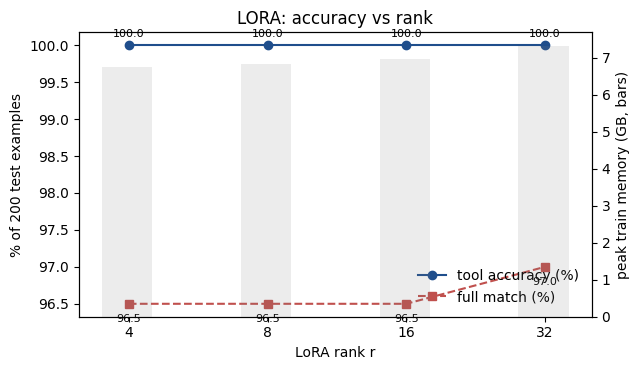

In [20]:
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(sec3["r"], sec3["tool_correct"] / 2, "o-", label="tool accuracy (%)", color="#1F4E8C")
ax.plot(sec3["r"], sec3["full_match"] / 2, "s--", label="full match (%)", color="#C0504D")
for r, t, f in zip(sec3["r"], sec3["tool_correct"] / 2, sec3["full_match"] / 2):
    ax.annotate(f"{t:.1f}", (r, t), textcoords="offset points", xytext=(0, 6), ha="center", fontsize=8)
    ax.annotate(f"{f:.1f}", (r, f), textcoords="offset points", xytext=(0, -13), ha="center", fontsize=8)
ax.set_xscale("log", base=2); ax.set_xticks([4, 8, 16, 32]); ax.set_xticklabels([4, 8, 16, 32])
ax.set_xlabel("LoRA rank r"); ax.set_ylabel("% of 200 test examples")
ax.set_title(f"{best_method.upper()}: accuracy vs rank")
ax2 = ax.twinx()
ax2.bar(sec3["r"], sec3["peak_train_mem_gb"], width=sec3["r"] * 0.25, alpha=0.15, color="gray")
ax2.set_ylabel("peak train memory (GB, bars)")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.savefig(f"{OUT}/rank_vs_accuracy.png", dpi=200); plt.show()

## Section 4 helpers: where the best model still breaks

In [21]:
overall_best = max(rank_rows, key=lambda x: (x["full_match"], x["tool_correct"], -x["r"]))["run"]
print("best overall run:", overall_best)
recs = [json.loads(l) for l in open(f"{OUT}/{overall_best}_preds.jsonl")]
wrong = [r for r in recs if not r["full_match"]]
print(len(wrong), "wrong out of", len(recs))
print(pd.Series([r["error_type"] for r in wrong]).value_counts())

best overall run: lora_r32
6 wrong out of 200
wrong argument value    3
made-up argument        2
missing argument        1
Name: count, dtype: int64


In [22]:
# pick up to 5 failures, one per error type first so the examples are varied
picked, seen = [], set()
for r in wrong:
    if r["error_type"] not in seen:
        picked.append(r); seen.add(r["error_type"])
for r in wrong:
    if len(picked) >= 5:
        break
    if r not in picked:
        picked.append(r)
for i, r in enumerate(picked[:5], 1):
    print(f"--- {i}. {r['error_type']}")
    print("USER:", r["user"][:300])
    print("GOLD:", json.dumps(r["gold"]))
    print("PRED:", r["pred"][:300])
json.dump(picked[:5], open(f"{OUT}/failures_best.json", "w"), indent=1)

--- 1. wrong argument value
USER: Hi, I have a sentence in French that I need translated to English. The sentence is "Je suis très heureux de vous rencontrer".
GOLD: {"name": "translate_text", "arguments": {"text": "Je suis tr\u00e8s heureux de vous rencontrer", "source_language": "fr", "target_language": "en"}}
PRED: {"name": "translate_text", "arguments": {"text": "Je suis tr\u00e8s heureux de vous rencontrer", "source_language": "French", "target_language": "English"}}
--- 2. missing argument
USER: I am in New York and I am craving for some Italian food. Can you find some nearby Italian restaurants?
GOLD: {"name": "find_nearby_restaurants", "arguments": {"location": "New York", "cuisine": "Italian", "radius": 5000}}
PRED: {"name": "find_nearby_restaurants", "arguments": {"location": "New York", "cuisine": "Italian"}}
--- 3. made-up argument
USER: I need images of sunsets.
GOLD: {"name": "search_images", "arguments": {"keywords": ["sunset"]}}
PRED: {"name": "search_images", "argument

In [23]:
probe = json.load(open(f"{OUT}/{overall_best}_probe.json"))
pd.DataFrame([{"query": p["query"], "gold": p["gold"], "pred_name": p["pred_name"], "pred": p["pred"][:120]} for p in probe])

,query,gold,pred_name,pred
0,Where is my order 58213? I placed it last Tues...,check_order_status,check_order_status,"{""name"": ""check_order_status"", ""arguments"": {""..."
1,When will order 77120 be delivered?,check_order_status,check_order_status,"{""name"": ""check_order_status"", ""arguments"": {""..."
2,Has my order A-4410 shipped yet?,check_order_status,track_shipment,"{""name"": ""track_shipment"", ""arguments"": {""trac..."
3,Can you tell me the expected delivery date for...,check_order_status,check_order_status,"{""name"": ""check_order_status"", ""arguments"": {""..."
4,"I want my money back for order 33102, the shoe...",initiate_refund,initiate_refund,"{""name"": ""initiate_refund"", ""arguments"": {""ord..."
5,"Please refund order 55017, the blender arrived...",initiate_refund,initiate_refund,"{""name"": ""initiate_refund"", ""arguments"": {""ord..."
6,Order 12009 never arrived and I'd like a refund.,initiate_refund,initiate_refund,"{""name"": ""initiate_refund"", ""arguments"": {""ord..."
7,"Cancel and refund order 64400, I was charged t...",initiate_refund,initiate_refund,"{""name"": ""initiate_refund"", ""arguments"": {""ord..."
8,Track parcel TRK-883920 for me.,track_shipment,track_shipment,"{""name"": ""track_shipment"", ""arguments"": {""trac..."
9,Where exactly is the courier with tracking num...,track_shipment,track_shipment,"{""name"": ""track_shipment"", ""arguments"": {""trac..."


In [24]:
# zip the results folder (without the adapter weights) so it can be downloaded in one go
import zipfile
with zipfile.ZipFile("q2_results.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for f in os.listdir(OUT):
        if os.path.isfile(f"{OUT}/{f}"):
            z.write(f"{OUT}/{f}", f"results/{f}")
print("download q2_results.zip from the Files panel, or copy the AssignmentBeta_Q2 folder from Drive")

download q2_results.zip from the Files panel, or copy the AssignmentBeta_Q2 folder from Drive
